# Angular clustering w(theta) — DP2 Object catalog + photo-z

Builds a MagLim-style lens galaxy sample from Rubin DP2, masks it with the DP2 survey
property maps, generates randoms, measures the raw angular correlation function w(theta) in
tomographic bins with TreeCorr, diagnoses observational systematics, and fits a linear
decontamination weight to flatten them.

**Region:** a contiguous ~100-300 deg² patch of the main (wide, non-DDF) coadd footprint,
centered on the Week 7 coordinates (345, -8.2). Increase `RADIUS_DEG` to grow the patch, up
to the full footprint.

**Pipeline:**
1. Select extended sources with clean i-band flags (Section 2).
2. Join photo-z on `objectId` (Section 3).
3. Apply a MagLim-style cut and split into tomographic bins (Section 4).
4. Mask on depth, griz coverage, and stellar density (Section 6).
5. Generate randoms matching the mask (Section 7).
6. Measure raw w(theta) per bin with TreeCorr (Section 8).
7. Diagnose systematics trends (Section 9).
8. Fit and apply linear decontamination weights, and recompute w(theta) (Section 10).

**Data products:** `dp2.Object` (TAP), `object_photoz` (LSDB/HATS), DP2 survey property maps
(Butler).

## 1. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import healpy as hp
import hpgeom as hpg
import healsparse
import treecorr
import lsdb
from upath import UPath
from lsst.daf.butler import Butler
from lsst.rsp import RSPDiscovery


### 1.1. Region and selection parameters

`TEST_MODE = True` shrinks the query to a ~0.3 deg radius cone (~0.3 deg²) so the whole
notebook — query, photo-z join, cuts, plots — runs end to end in well under a minute, using
the exact same code path as the full run. Set `TEST_MODE = False` once the pipeline checks
out, to use the full ~113 deg² region.

`RADIUS_DEG` sets a circular query region of area `pi * RADIUS_DEG**2`. The full-run default
below is ~113 deg², in the middle of the requested 100-300 deg² range, chosen to keep the TAP
query and the pandas/LSDB join comfortably within class time. Ambitious students can grow
`RADIUS_DEG` toward the full footprint — see the note in Section 5 about the join size limit.

`FAINT_PRECUT` is a loose faint-end cut applied at the TAP stage only, to bound the amount of
data pulled before the photo-z join. It is well below the typical depth where the exact
MagLim relation would cut anyway (`i = 4*z_phot + 18` reaches 23 mag only for `z_phot > 1.25`),
so it should not bias the final sample for a low-to-moderate redshift lens selection. The
true MagLim-style cut is re-applied exactly, using the joined photo-z, in Section 4.

`FETCH_FULL_SYSTEMATICS` controls how many Butler survey-property maps Section 6 fetches.
`False` (the default) fetches only the i-band depth map — the one map the footprint mask
actually needs — which is both faster and enough to get a properly masked w(theta). `True`
additionally fetches PSF size, sky noise, exposure time, and griz coverage, which Sections 9
and 10 need for the full systematics diagnostics and decontamination weights. Either way,
every map fetch is cached to disk under `MAP_CACHE_DIR` (see Section 6.2), so repeated runs
with the same parameters skip the slow Butler I/O entirely after the first.

In [2]:
TEST_MODE = True  # True: tiny region for a fast end-to-end check; False: full run
FETCH_FULL_SYSTEMATICS = False  # True: all 7 Butler maps (needed for Sections 9-10)

RA_CENTER = 345.0
DEC_CENTER = -8.2
#RADIUS_DEG = 0.3 if TEST_MODE else 6.0
RADIUS_DEG = 1.0 if TEST_MODE else 6.0

BAND = 'i'
MAG_BRIGHT = 17.5
FAINT_PRECUT = 23.0
MAGLIM_SLOPE = 4.0
MAGLIM_INTERCEPT = 18.0

N_ZBINS = 4
Z_EDGES = np.linspace(0.0, 1.0, N_ZBINS + 1)

MASK_NSIDE = 4096
DIAG_NSIDE = 512
DEPTH_MARGIN_MAG = 1.0
STAR_MAG_BRIGHT = 17.5
STAR_MAG_FAINT = 21.0
STELLAR_DENSITY_PERCENTILE = 90.0

MAP_CACHE_DIR = os.path.expanduser('~/notebooks/.map_cache')

RAND_FACTOR = 15
MAX_RANDOMS = 2_000_000

TC_MIN_SEP_ARCMIN = 1.0
TC_MAX_SEP_ARCMIN = min(250.0, RADIUS_DEG * 60.0 * 0.5)
TC_NBINS = 15

area_deg2 = np.pi * RADIUS_DEG**2
print('Query region: {:.2f} deg radius, {:.2f} deg^2{}'.format(
    RADIUS_DEG, area_deg2, ' [TEST_MODE]' if TEST_MODE else ''))
print('Systematics maps:', 'all 7 (full)' if FETCH_FULL_SYSTEMATICS else 'i-band depth only')


Query region: 1.00 deg radius, 3.14 deg^2 [TEST_MODE]
Systematics maps: i-band depth only


### 1.2. Connect to the TAP service

In [3]:
discovery = RSPDiscovery("dp2")
service = discovery.get_tap_client()
assert service is not None


In [4]:
def run_query(query):
    """Submit an ADQL query as an async TAP job and return an astropy table."""
    job = service.submit_job(query)
    job.run()
    job.wait(phases=['COMPLETED', 'ERROR'])
    print('Job phase is', job.phase)
    if job.phase == 'ERROR':
        job.raise_if_error()
    assert job.phase == 'COMPLETED'
    table = job.fetch_result().to_table()
    job.delete()
    return table


## 2. Query the Object catalog

Select extended sources with clean i-band photometry flags, in the region, between the
bright limit and the faint pre-cut. The flag set follows the
[DP2 flag use examples](https://dp2.lsst.io/products/flags/flag_usage.html), with
`{band}_psfFlux_flag` swapped for `{band}_cModel_flag` since the selection is built on
CModel photometry (the recommended substitution for whichever flux type is actually used).

In [5]:
columns = [
    'objectId', 'coord_ra', 'coord_dec', 'refExtendedness', 'ebv',
    '{0}_cModelMag'.format(BAND), '{0}_cModelMagErr'.format(BAND),
    '{0}_inputCount'.format(BAND), '{0}_cModel_flag'.format(BAND),
    '{0}_invalidPsfFlag'.format(BAND),
    '{0}_pixelFlags_saturatedCenter'.format(BAND),
    '{0}_pixelFlags_interpolatedCenter'.format(BAND),
]

query = (
    "SELECT " + ", ".join(columns) + " "
    "FROM dp2.Object "
    "WHERE CONTAINS(POINT('ICRS', coord_ra, coord_dec), "
    "CIRCLE('ICRS', {ra}, {dec}, {radius})) = 1 "
    "AND refExtendedness = 1 "
    "AND {b}_inputCount > 0 "
    "AND {b}_cModel_flag = 0 "
    "AND {b}_invalidPsfFlag = 0 "
    "AND {b}_pixelFlags_saturatedCenter = 0 "
    "AND {b}_pixelFlags_interpolatedCenter = 0 "
    "AND {b}_cModelMag > {bright} "
    "AND {b}_cModelMag < {faint}"
).format(ra=RA_CENTER, dec=DEC_CENTER, radius=RADIUS_DEG, b=BAND,
         bright=MAG_BRIGHT, faint=FAINT_PRECUT)
print(query)


SELECT objectId, coord_ra, coord_dec, refExtendedness, ebv, i_cModelMag, i_cModelMagErr, i_inputCount, i_cModel_flag, i_invalidPsfFlag, i_pixelFlags_saturatedCenter, i_pixelFlags_interpolatedCenter FROM dp2.Object WHERE CONTAINS(POINT('ICRS', coord_ra, coord_dec), CIRCLE('ICRS', 345.0, -8.2, 1.0)) = 1 AND refExtendedness = 1 AND i_inputCount > 0 AND i_cModel_flag = 0 AND i_invalidPsfFlag = 0 AND i_pixelFlags_saturatedCenter = 0 AND i_pixelFlags_interpolatedCenter = 0 AND i_cModelMag > 17.5 AND i_cModelMag < 23.0


In [6]:
obj_table = run_query(query)
obj_df = obj_table.to_pandas()
print(len(obj_df), 'extended, clean-flag objects in the region')


Job phase is COMPLETED
90416 extended, clean-flag objects in the region


In [7]:
MAX_JOIN_ROWS = 1_000_000
if len(obj_df) > MAX_JOIN_ROWS:
    print('Warning: {} rows exceeds the recommended size for an in-memory LSDB join '
          '({}). Reduce RADIUS_DEG or tighten FAINT_PRECUT before continuing.'
          .format(len(obj_df), MAX_JOIN_ROWS))


## 3. Join photo-z on `objectId`

DP2 photo-z estimates are distributed only as an LSDB/HATS catalog (`object_photoz`), not as
a TAP-joinable table. Convert the Object query result to an LSDB catalog, open the photo-z
catalog over the same region, and do an inner join on `objectId`.

In [8]:
base_path = UPath("/rubin/lsdb_data/dp2")

obj_df_renamed = obj_df.rename(columns={'coord_ra': 'ra', 'coord_dec': 'dec'})
obj_cat = lsdb.from_dataframe(obj_df_renamed, catalog_name="object")


In [9]:
pz_cat_full = lsdb.open_catalog(base_path / "object_photoz")
pz_codes = sorted({col.split('_')[0] for col in pz_cat_full.columns if col.endswith('_z_best')})
print('Available photo-z estimators:', pz_codes)

PZ_CODE = pz_codes[0]
pz_col = '{}_z_median'.format(PZ_CODE)
print('Using', pz_col, 'as z_phot')


Available photo-z estimators: ['bpz', 'dnf', 'fzboost', 'gpz', 'knn', 'tpz']
Using bpz_z_median as z_phot


In [10]:
pz_cat = lsdb.open_catalog(base_path / "object_photoz",
                           columns=['objectId', 'ra', 'dec', pz_col])
pz_cat_region = pz_cat.cone_search(ra=RA_CENTER, dec=DEC_CENTER,
                                   radius_arcsec=RADIUS_DEG * 3600.0)

joined_cat = pz_cat_region.join(
    obj_cat,
    left_on='objectId',
    right_on='objectId',
    suffix_method='all_columns',
)
clustering_df = joined_cat.compute()
print(len(clustering_df), 'objects with both Object and photo-z measurements')


Computing Catalog:   0%|          | 0/13 [00:00<?, ?it/s]

90416 objects with both Object and photo-z measurements


## 4. Apply the exact MagLim-style cut and split into tomographic bins

In [11]:
i_col = '{0}_cModelMag_object'.format(BAND)
z_col = '{0}_object_photoz'.format(pz_col)

clustering_df = clustering_df.rename(columns={
    i_col: 'i_mag',
    z_col: 'z_phot',
    'ebv_object': 'ebv',
    'objectId_object': 'objectId',
    'ra_object': 'ra',
    'dec_object': 'dec',
})

maglim_cut = (
    (clustering_df['i_mag'] > MAG_BRIGHT)
    & (clustering_df['i_mag'] < MAGLIM_SLOPE * clustering_df['z_phot'] + MAGLIM_INTERCEPT)
    & (clustering_df['z_phot'] >= Z_EDGES[0])
    & (clustering_df['z_phot'] < Z_EDGES[-1])
)
galaxies = clustering_df.loc[maglim_cut,
                             ['objectId', 'ra', 'dec', 'i_mag', 'z_phot', 'ebv']].reset_index(drop=True)
galaxies['zbin'] = np.digitize(galaxies['z_phot'], Z_EDGES[1:-1])
print(len(galaxies), 'galaxies pass the MagLim-style cut and lie in [{:.2f}, {:.2f})'.format(
    Z_EDGES[0], Z_EDGES[-1]))
for b in range(N_ZBINS):
    print('  bin {}: {:.2f} <= z < {:.2f}, {} galaxies'.format(
        b, Z_EDGES[b], Z_EDGES[b + 1], np.sum(galaxies['zbin'] == b)))


4778 galaxies pass the MagLim-style cut and lie in [0.00, 1.00)
  bin 0: 0.00 <= z < 0.25, 765 galaxies
  bin 1: 0.25 <= z < 0.50, 1313 galaxies
  bin 2: 0.50 <= z < 0.75, 1202 galaxies
  bin 3: 0.75 <= z < 1.00, 1498 galaxies


## 5. Sanity-check plots

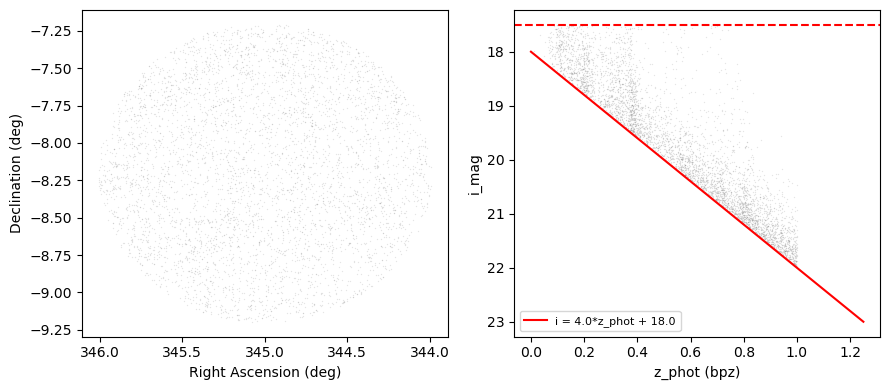

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4))

ax1.plot(galaxies['ra'], galaxies['dec'], 'o', ms=1, mew=0, alpha=0.2, color='grey')
ax1.set_xlabel('Right Ascension (deg)')
ax1.set_ylabel('Declination (deg)')
ax1.invert_xaxis()

ax2.plot(galaxies['z_phot'], galaxies['i_mag'], 'o', ms=1, mew=0, alpha=0.2, color='grey')
z_line = np.linspace(0, (23 - MAGLIM_INTERCEPT) / MAGLIM_SLOPE, 100)
ax2.plot(z_line, MAGLIM_SLOPE * z_line + MAGLIM_INTERCEPT, 'r-', lw=1.5,
         label='i = {}*z_phot + {}'.format(MAGLIM_SLOPE, MAGLIM_INTERCEPT))
ax2.axhline(MAG_BRIGHT, color='r', ls='--', lw=1.5)
ax2.set_xlabel('z_phot ({})'.format(PZ_CODE))
ax2.set_ylabel('i_mag')
ax2.invert_yaxis()
ax2.legend(fontsize=8)

plt.tight_layout()
plt.show()


## 6. Mask

Build a footprint mask at `MASK_NSIDE` (~4096, ~50 arcsec pixels) from the DP2 survey
property maps (accessed via the Butler) and a stellar density map built from the Object
catalog. A pixel survives the mask if:
- the i-band coadd depth (`psf_maglim`) is at least `DEPTH_MARGIN_MAG` mag deeper than the
  faintest magnitude the sample's MagLim cut reaches, so completeness stays flat across the
  footprint,
- the pixel has coverage (a measured depth) in all of `griz`,
- the local stellar density is below the `STELLAR_DENSITY_PERCENTILE`-th percentile.

### 6.1. Connect to the Butler

In [13]:
butler = Butler("dp2", collections="dp2")


### 6.2. Helper to fetch a region-restricted survey property map

Survey property maps are delivered as all-sky HealSparse files, which are far too large to
read at full resolution. Read only the low-resolution coverage map first, keep the pixels
near the region of interest, and pass those to the Butler so only that cutout is read at
`MASK_NSIDE`.

`get_region_map_cached` wraps this in a disk cache under `MAP_CACHE_DIR`: each region cutout
is written to a local FITS file keyed by dataset, band, and region parameters, so re-running
the notebook (or switching `FETCH_FULL_SYSTEMATICS`) only pays the Butler I/O cost once per
distinct map.

In [14]:
def angular_sep_deg(ra0, dec0, ra1, dec1):
    ra0, dec0, ra1, dec1 = np.radians(ra0), np.radians(dec0), np.radians(ra1), np.radians(dec1)
    cos_sep = np.sin(dec0) * np.sin(dec1) + np.cos(dec0) * np.cos(dec1) * np.cos(ra1 - ra0)
    return np.degrees(np.arccos(np.clip(cos_sep, -1.0, 1.0)))


def get_region_map(dataset_type, band, nside, ra_center, dec_center, radius_deg):
    """Fetch a Butler consolidated survey-property map, restricted to a cone."""
    cov = butler.get('{}.coverage'.format(dataset_type), band=band, skymap='lsst_cells_v2')
    cov_pix = np.where(cov.coverage_mask)[0]
    cov_ra, cov_dec = hpg.pixel_to_angle(cov.nside_coverage, cov_pix)
    pad_deg = radius_deg + hpg.nside_to_resolution(cov.nside_coverage, units='degrees')
    nearby = angular_sep_deg(ra_center, dec_center, cov_ra, cov_dec) < pad_deg
    region_cov_pix = cov_pix[nearby]
    return butler.get(dataset_type, band=band, skymap='lsst_cells_v2',
                      parameters={'pixels': list(region_cov_pix), 'degrade_nside': nside})


os.makedirs(MAP_CACHE_DIR, exist_ok=True)


def get_region_map_cached(dataset_type, band, nside, ra_center, dec_center, radius_deg):
    """Like get_region_map, but caches the cutout to disk to skip the Butler fetch on reruns."""
    key = '{}_{}_nside{}_ra{:.3f}_dec{:.3f}_r{:.3f}.hsp'.format(
        dataset_type, band, nside, ra_center, dec_center, radius_deg)
    path = os.path.join(MAP_CACHE_DIR, key)
    if os.path.exists(path):
        print('  loading from cache:', key)
        return healsparse.HealSparseMap.read(path)
    print('  fetching from Butler:', key)
    hspmap = get_region_map(dataset_type, band, nside, ra_center, dec_center, radius_deg)
    hspmap.write(path, clobber=True)
    return hspmap


### 6.3. Fetch the i-band depth map (and, if requested, the rest)

The mask only strictly needs `psf_maglim` (the depth cut). The other three systematics maps
(`psf_size`, `sky_noise`, `exposure_time`) and the `griz` coverage check are only fetched when
`FETCH_FULL_SYSTEMATICS = True`, since they're only used by the diagnostics and weights in
Sections 9-10. Coverage in `g`, `r`, `z` is checked using the same `psf_maglim` dataset in
each band (a measured value means coverage).

In [15]:
DEPTH_LIMIT_I = MAGLIM_SLOPE * Z_EDGES[-1] + MAGLIM_INTERCEPT + DEPTH_MARGIN_MAG
print('Requiring i-band depth deeper than {:.2f} mag ({:.1f} mag beyond the sample faint limit)'
      .format(DEPTH_LIMIT_I, DEPTH_MARGIN_MAG))

maglim_map = get_region_map_cached('deepCoadd_psf_maglim_consolidated_map_weighted_mean', BAND,
                                   MASK_NSIDE, RA_CENTER, DEC_CENTER, RADIUS_DEG)

if FETCH_FULL_SYSTEMATICS:
    psfsize_map = get_region_map_cached('deepCoadd_psf_size_consolidated_map_weighted_mean', BAND,
                                        MASK_NSIDE, RA_CENTER, DEC_CENTER, RADIUS_DEG)
    skynoise_map = get_region_map_cached('deepCoadd_sky_noise_consolidated_map_weighted_mean', BAND,
                                         MASK_NSIDE, RA_CENTER, DEC_CENTER, RADIUS_DEG)
    exptime_map = get_region_map_cached('deepCoadd_exposure_time_consolidated_map_sum', BAND,
                                        MASK_NSIDE, RA_CENTER, DEC_CENTER, RADIUS_DEG)
    other_bands = [b for b in ['g', 'r', 'i', 'z'] if b != BAND]
    coverage_maps = {b: get_region_map_cached('deepCoadd_psf_maglim_consolidated_map_weighted_mean', b,
                                              MASK_NSIDE, RA_CENTER, DEC_CENTER, RADIUS_DEG)
                     for b in other_bands}
    print('Fetched all 7 survey property maps')
else:
    coverage_maps = {}
    print('FETCH_FULL_SYSTEMATICS=False: fetched only the i-band depth map')


Requiring i-band depth deeper than 23.00 mag (1.0 mag beyond the sample faint limit)
  fetching from Butler: deepCoadd_psf_maglim_consolidated_map_weighted_mean_i_nside4096_ra345.000_dec-8.200_r1.000.hsp
FETCH_FULL_SYSTEMATICS=False: fetched only the i-band depth map


### 6.4. Evaluate the maps and the stellar density on a pixel grid covering the region

In [16]:
def pixels_at(ra, dec, nside=MASK_NSIDE):
    return hp.ang2pix(nside, np.asarray(ra), np.asarray(dec), nest=True, lonlat=True)


def count_in_pixels(ra, dec, pix_grid):
    pix = pixels_at(ra, dec)
    idx = np.clip(np.searchsorted(pix_grid, pix), 0, len(pix_grid) - 1)
    found = pix_grid[idx] == pix
    counts = np.zeros(len(pix_grid))
    np.add.at(counts, idx[found], 1)
    return counts


mask_vec = hp.ang2vec(RA_CENTER, DEC_CENTER, lonlat=True)
mask_pix = np.sort(hp.query_disc(MASK_NSIDE, mask_vec, np.radians(RADIUS_DEG), nest=True))
mask_ra, mask_dec = hp.pix2ang(MASK_NSIDE, mask_pix, nest=True, lonlat=True)
pixel_area_deg2 = hp.nside2pixarea(MASK_NSIDE, degrees=True)
print('{} candidate pixels at nside={} ({:.6f} deg^2 each)'.format(
    len(mask_pix), MASK_NSIDE, pixel_area_deg2))

i_maglim_vals = maglim_map.get_values_pos(mask_ra, mask_dec)

coverage_ok = np.ones(len(mask_pix), dtype=bool)
if FETCH_FULL_SYSTEMATICS:
    i_psfsize_vals = psfsize_map.get_values_pos(mask_ra, mask_dec)
    i_skynoise_vals = skynoise_map.get_values_pos(mask_ra, mask_dec)
    i_exptime_vals = exptime_map.get_values_pos(mask_ra, mask_dec)
    for b, m in coverage_maps.items():
        coverage_ok &= (m.get_values_pos(mask_ra, mask_dec) > 0)


15335 candidate pixels at nside=4096 (0.000205 deg^2 each)


In [17]:
star_columns = ['coord_ra', 'coord_dec']
star_query = (
    "SELECT " + ", ".join(star_columns) + " "
    "FROM dp2.Object "
    "WHERE CONTAINS(POINT('ICRS', coord_ra, coord_dec), "
    "CIRCLE('ICRS', {ra}, {dec}, {radius})) = 1 "
    "AND refExtendedness = 0 "
    "AND {b}_inputCount > 0 "
    "AND {b}_psfFlux_flag = 0 "
    "AND {b}_invalidPsfFlag = 0 "
    "AND {b}_pixelFlags_saturatedCenter = 0 "
    "AND {b}_pixelFlags_interpolatedCenter = 0 "
    "AND {b}_psfMag > {bright} "
    "AND {b}_psfMag < {faint}"
).format(ra=RA_CENTER, dec=DEC_CENTER, radius=RADIUS_DEG, b=BAND,
         bright=STAR_MAG_BRIGHT, faint=STAR_MAG_FAINT)
star_df = run_query(star_query).to_pandas()
print(len(star_df), 'point sources for the stellar density map')

star_counts = count_in_pixels(star_df['coord_ra'].values, star_df['coord_dec'].values, mask_pix)
star_density = star_counts / pixel_area_deg2
density_thresh = np.percentile(star_density[coverage_ok], STELLAR_DENSITY_PERCENTILE)
low_stellar_density = star_density <= density_thresh
print('Stellar density veto threshold ({:.0f}th pct): {:.1f} stars/deg^2'.format(
    STELLAR_DENSITY_PERCENTILE, density_thresh))


Job phase is COMPLETED
9762 point sources for the stellar density map
Stellar density veto threshold (90th pct): 9760.6 stars/deg^2


### 6.5. Combine into the final mask and apply it to the galaxy sample

In [18]:
valid_mask = (i_maglim_vals > DEPTH_LIMIT_I) & coverage_ok & low_stellar_density
valid_pix = mask_pix[valid_mask]
mask_area_deg2 = valid_mask.sum() * pixel_area_deg2
print('{} of {} pixels pass the mask ({:.1f}%), unmasked area {:.2f} deg^2'.format(
    valid_mask.sum(), len(mask_pix), 100 * valid_mask.mean(), mask_area_deg2))


def in_mask(ra, dec):
    pix = pixels_at(ra, dec)
    idx = np.clip(np.searchsorted(valid_pix, pix), 0, len(valid_pix) - 1)
    return valid_pix[idx] == pix


galaxies = galaxies.loc[in_mask(galaxies['ra'].values, galaxies['dec'].values)].reset_index(drop=True)
print(len(galaxies), 'galaxies remain after the mask')
for b in range(N_ZBINS):
    print('  bin {}: {} galaxies'.format(b, np.sum(galaxies['zbin'] == b)))


14923 of 15335 pixels pass the mask (97.3%), unmasked area 3.06 deg^2
4634 galaxies remain after the mask
  bin 0: 741 galaxies
  bin 1: 1275 galaxies
  bin 2: 1176 galaxies
  bin 3: 1442 galaxies


## 7. Randoms

Generate randoms uniformly over the unmasked footprint: pick a random valid `MASK_NSIDE`
pixel, then jitter to a random sub-pixel position `RAND_OVERSAMPLE` times finer, which
approximates continuous uniform sampling within the pixel. The same random catalog is reused
for every tomographic bin, since the mask does not depend on redshift.

In [19]:
N_RANDOMS = min(MAX_RANDOMS, RAND_FACTOR * len(galaxies))
RAND_OVERSAMPLE = 16
rand_nside = MASK_NSIDE * RAND_OVERSAMPLE
sub_factor2 = RAND_OVERSAMPLE**2

rng = np.random.default_rng(0)
chosen_coarse = valid_pix[rng.integers(0, len(valid_pix), size=N_RANDOMS)]
sub_offset = rng.integers(0, sub_factor2, size=N_RANDOMS)
fine_pix = chosen_coarse.astype(np.int64) * sub_factor2 + sub_offset
rand_ra, rand_dec = hp.pix2ang(rand_nside, fine_pix, nest=True, lonlat=True)
print(N_RANDOMS, 'randoms generated ({:.1f}x the galaxy count)'.format(N_RANDOMS / len(galaxies)))


69510 randoms generated (15.0x the galaxy count)


## 8. Raw angular correlation function with TreeCorr

Landy-Szalay estimator, `w = (DD - 2*DR + RR) / RR`, computed per tomographic bin against
the shared random catalog.

In [20]:
rand_cat = treecorr.Catalog(ra=rand_ra, dec=rand_dec, ra_units='deg', dec_units='deg')
rr = treecorr.NNCorrelation(min_sep=TC_MIN_SEP_ARCMIN, max_sep=TC_MAX_SEP_ARCMIN,
                            nbins=TC_NBINS, sep_units='arcmin')
rr.process(rand_cat)


def compute_wtheta(ra, dec, w=None):
    cat = treecorr.Catalog(ra=ra, dec=dec, w=w, ra_units='deg', dec_units='deg')
    dd = treecorr.NNCorrelation(min_sep=TC_MIN_SEP_ARCMIN, max_sep=TC_MAX_SEP_ARCMIN,
                                nbins=TC_NBINS, sep_units='arcmin')
    dr = treecorr.NNCorrelation(min_sep=TC_MIN_SEP_ARCMIN, max_sep=TC_MAX_SEP_ARCMIN,
                                nbins=TC_NBINS, sep_units='arcmin')
    dd.process(cat)
    dr.process(cat, rand_cat)
    xi, varxi = dd.calculateXi(rr=rr, dr=dr)
    return dd.meanr, xi, np.sqrt(varxi)


raw_results = {}
for b in range(N_ZBINS):
    sel = (galaxies['zbin'] == b).values
    theta, xi, err = compute_wtheta(galaxies['ra'][sel].values, galaxies['dec'][sel].values)
    raw_results[b] = (theta, xi, err)
    print('bin {}: {} galaxies'.format(b, sel.sum()))


bin 0: 741 galaxies
bin 1: 1275 galaxies
bin 2: 1176 galaxies
bin 3: 1442 galaxies


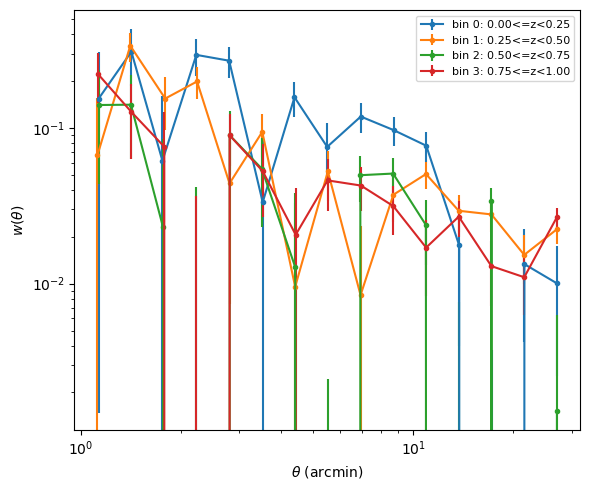

In [21]:
fig, ax = plt.subplots(figsize=(6, 5))
for b in range(N_ZBINS):
    theta, xi, err = raw_results[b]
    ax.errorbar(theta, xi, yerr=err, fmt='o-', ms=3,
               label='bin {}: {:.2f}<=z<{:.2f}'.format(b, Z_EDGES[b], Z_EDGES[b + 1]))
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r'$\theta$ (arcmin)')
ax.set_ylabel(r'$w(\theta)$')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


## 9. Systematics diagnostics

For the full (pre-tomographic) MagLim sample, compare galaxy density to each systematic map
degraded to `DIAG_NSIDE` (256-512), binned into deciles of the systematic value. A flat
`n_gal / <n> = 1` trend indicates no significant systematic dependence — the classic DES
validation figure. E(B-V) has no dedicated Butler map, so it is built here by averaging the
per-object `ebv` column (pulled with the Object query) in each pixel.

In [22]:
def weighted_sum_in_pixels(ra, dec, values, pix_grid):
    pix = pixels_at(ra, dec)
    idx = np.clip(np.searchsorted(pix_grid, pix), 0, len(pix_grid) - 1)
    found = pix_grid[idx] == pix
    sums = np.zeros(len(pix_grid))
    counts = np.zeros(len(pix_grid))
    np.add.at(sums, idx[found], values[found])
    np.add.at(counts, idx[found], 1)
    return sums, counts


ebv_sum, ebv_count = weighted_sum_in_pixels(obj_df_renamed['ra'].values, obj_df_renamed['dec'].values,
                                            obj_df_renamed['ebv'].values, mask_pix)
with np.errstate(invalid='ignore', divide='ignore'):
    ebv_native = np.where(ebv_count > 0, ebv_sum / np.maximum(ebv_count, 1), np.nan)

systematic_labels = {
    'i_depth': 'i-band depth (maglim)',
    'ebv': 'E(B-V)',
    'stellar_density': 'stellar density (/deg^2)',
}
systematics_native = {
    'i_depth': i_maglim_vals,
    'ebv': ebv_native,
    'stellar_density': star_density,
}
if FETCH_FULL_SYSTEMATICS:
    systematic_labels.update({
        'i_psf_size': 'i-band PSF size',
        'i_sky_noise': 'i-band sky noise',
        'i_exptime': 'i-band exposure time',
    })
    systematics_native.update({
        'i_psf_size': i_psfsize_vals,
        'i_sky_noise': i_skynoise_vals,
        'i_exptime': i_exptime_vals,
    })
else:
    print('FETCH_FULL_SYSTEMATICS=False: diagnostics/weights use only',
         list(systematic_labels.keys()))

systematics_valid = {k: v[valid_mask] for k, v in systematics_native.items()}


FETCH_FULL_SYSTEMATICS=False: diagnostics/weights use only ['i_depth', 'ebv', 'stellar_density']


In [23]:
def degrade_pix(pix_fine, nside_fine, nside_coarse):
    shift = 2 * int(round(np.log2(nside_fine / nside_coarse)))
    return pix_fine >> shift


diag_pix_of_valid = degrade_pix(valid_pix, MASK_NSIDE, DIAG_NSIDE)
diag_unique, diag_inverse = np.unique(diag_pix_of_valid, return_inverse=True)
diag_area_deg2 = hp.nside2pixarea(DIAG_NSIDE, degrees=True)


def mean_per_diag_pixel(values):
    valid = ~np.isnan(values)
    sums = np.bincount(diag_inverse[valid], weights=values[valid], minlength=len(diag_unique))
    counts = np.bincount(diag_inverse[valid], minlength=len(diag_unique))
    with np.errstate(invalid='ignore', divide='ignore'):
        return np.where(counts > 0, sums / np.maximum(counts, 1), np.nan)


diag_values = {name: mean_per_diag_pixel(systematics_valid[name]) for name in systematic_labels}
valid_native_count_diag = np.bincount(diag_inverse, minlength=len(diag_unique))
diag_area_per_pix_deg2 = valid_native_count_diag * pixel_area_deg2


In [24]:
gal_counts_native = count_in_pixels(galaxies['ra'].values, galaxies['dec'].values, mask_pix)
gal_counts_native_valid = gal_counts_native[valid_mask]
n_gal_diag = np.bincount(diag_inverse, weights=gal_counts_native_valid, minlength=len(diag_unique))
mean_density = n_gal_diag.sum() / diag_area_per_pix_deg2.sum()
print('Mean galaxy density: {:.2f} / deg^2 over {} diagnostic pixels at nside={}'.format(
    mean_density, len(diag_unique), DIAG_NSIDE))

N_SYS_BINS = 8


def density_ratio_trend(sys_values, n_gal, area, mean_dens, nbins=N_SYS_BINS):
    good = ~np.isnan(sys_values) & (area > 0)
    edges = np.nanpercentile(sys_values[good], np.linspace(0, 100, nbins + 1))
    edges[0] -= 1e-6
    edges[-1] += 1e-6
    bin_idx = np.clip(np.digitize(sys_values[good], edges) - 1, 0, nbins - 1)
    x, y, yerr = [], [], []
    for k in range(nbins):
        sel = bin_idx == k
        if not np.any(sel):
            continue
        n_tot = n_gal[good][sel].sum()
        a_tot = area[good][sel].sum()
        dens = (n_tot / a_tot) / mean_dens
        err = dens / np.sqrt(max(n_tot, 1))
        x.append(np.average(sys_values[good][sel]))
        y.append(dens)
        yerr.append(err)
    return np.array(x), np.array(y), np.array(yerr)


Mean galaxy density: 1515.46 / deg^2 over 271 diagnostic pixels at nside=512


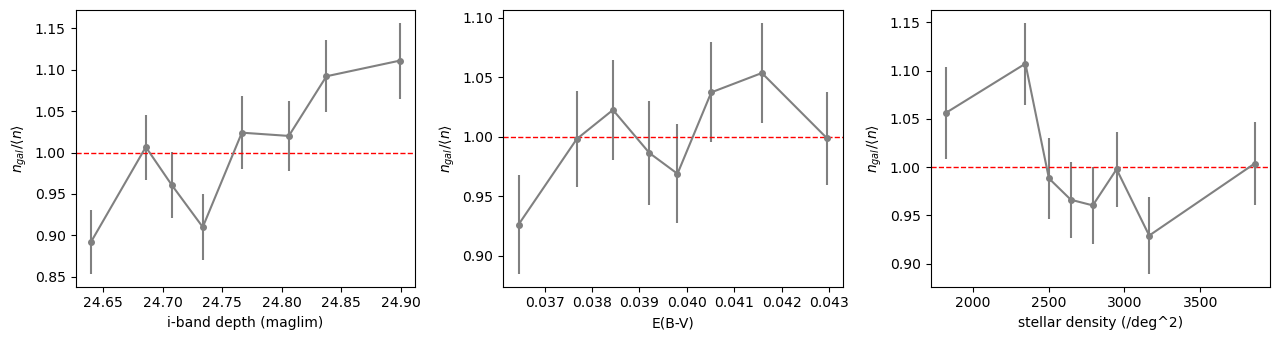

In [25]:
n_sys = len(systematic_labels)
ncols = min(3, n_sys)
nrows = int(np.ceil(n_sys / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.3 * ncols, 3.5 * nrows), squeeze=False)
axes = axes.flatten()
for ax, (name, label) in zip(axes, systematic_labels.items()):
    x, y, yerr = density_ratio_trend(diag_values[name], n_gal_diag, diag_area_per_pix_deg2, mean_density)
    ax.errorbar(x, y, yerr=yerr, fmt='o-', ms=4, color='grey')
    ax.axhline(1.0, color='r', ls='--', lw=1)
    ax.set_xlabel(label)
    ax.set_ylabel(r'$n_{gal}/\langle n \rangle$')
for ax in axes[n_sys:]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()


## 10. Weights: linear systematics decontamination

Fit a linear model for the fractional overdensity in terms of the (standardized)
systematics at `DIAG_NSIDE`, weighted by the unmasked area per diagnostic pixel. Each
galaxy's weight is `1 / (1 + sum_i a_i * s_i)`, evaluated at its own position, which should
flatten the Section 9 trends.

In [26]:
sys_names = list(systematic_labels.keys())
X_raw = np.column_stack([diag_values[name] for name in sys_names])
good = (diag_area_per_pix_deg2 > 0) & ~np.isnan(X_raw).any(axis=1)

X_mean = X_raw[good].mean(axis=0)
X_std = X_raw[good].std(axis=0)
X_std[X_std == 0] = 1.0
X_norm = (X_raw - X_mean) / X_std

y = (n_gal_diag / diag_area_per_pix_deg2) / mean_density - 1.0
area_weight = diag_area_per_pix_deg2

A = X_norm[good] * np.sqrt(area_weight[good])[:, None]
b_ = y[good] * np.sqrt(area_weight[good])
coeffs, _, _, _ = np.linalg.lstsq(A, b_, rcond=None)
print('Fitted systematics coefficients:')
for name, c in zip(sys_names, coeffs):
    print('  {:<16s} {:+.4f}'.format(name, c))


Fitted systematics coefficients:
  i_depth          +0.0615
  ebv              +0.0336
  stellar_density  -0.0255


In [27]:
def lookup_valid(values_at_valid_pix, ra, dec):
    pix = pixels_at(ra, dec)
    idx = np.clip(np.searchsorted(valid_pix, pix), 0, len(valid_pix) - 1)
    found = valid_pix[idx] == pix
    out = np.full(len(pix), np.nan)
    out[found] = values_at_valid_pix[idx[found]]
    return out


gal_ra = galaxies['ra'].values
gal_dec = galaxies['dec'].values
gal_sys = {
    'i_depth': maglim_map.get_values_pos(gal_ra, gal_dec),
    'ebv': galaxies['ebv'].values,
    'stellar_density': lookup_valid(systematics_valid['stellar_density'], gal_ra, gal_dec),
}
if FETCH_FULL_SYSTEMATICS:
    gal_sys.update({
        'i_psf_size': psfsize_map.get_values_pos(gal_ra, gal_dec),
        'i_sky_noise': skynoise_map.get_values_pos(gal_ra, gal_dec),
        'i_exptime': exptime_map.get_values_pos(gal_ra, gal_dec),
    })
X_gal = np.column_stack([gal_sys[name] for name in sys_names])
X_gal_norm = (X_gal - X_mean) / X_std
model = 1.0 + X_gal_norm @ coeffs
galaxies['weight'] = 1.0 / np.clip(model, 0.5, 2.0)
print('Weight stats: min {:.3f}, max {:.3f}, mean {:.3f}'.format(
    galaxies['weight'].min(), galaxies['weight'].max(), galaxies['weight'].mean()))


Weight stats: min 0.736, max 2.000, mean 1.019


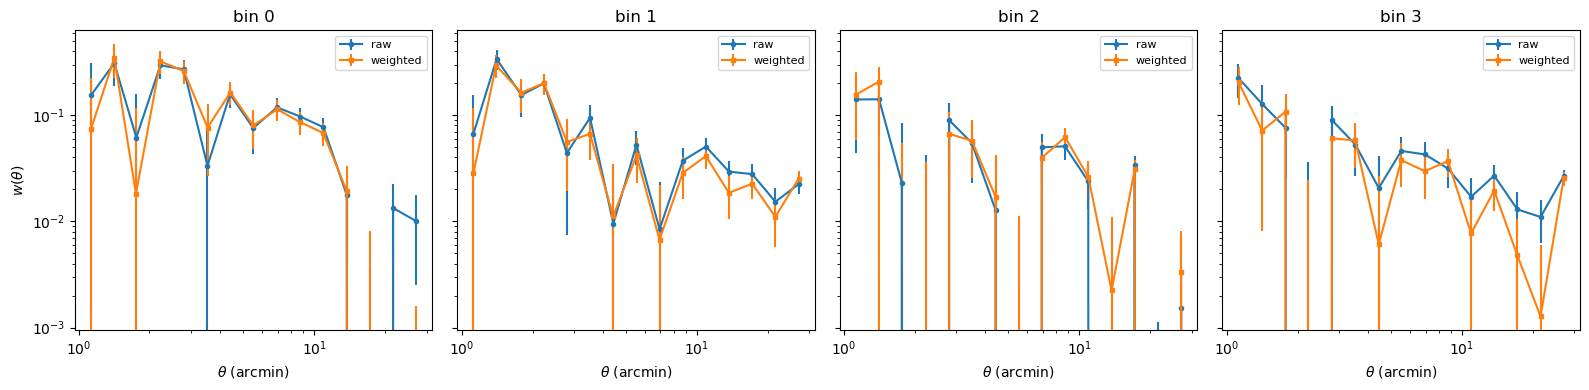

In [28]:
weighted_results = {}
for b in range(N_ZBINS):
    sel = (galaxies['zbin'] == b).values
    theta, xi, err = compute_wtheta(galaxies['ra'][sel].values, galaxies['dec'][sel].values,
                                    w=galaxies['weight'][sel].values)
    weighted_results[b] = (theta, xi, err)

fig, axes = plt.subplots(1, N_ZBINS, figsize=(4 * N_ZBINS, 4), sharey=True)
axes = np.atleast_1d(axes)
for b, ax in enumerate(axes):
    theta_r, xi_r, err_r = raw_results[b]
    theta_w, xi_w, err_w = weighted_results[b]
    ax.errorbar(theta_r, xi_r, yerr=err_r, fmt='o-', ms=3, label='raw')
    ax.errorbar(theta_w, xi_w, yerr=err_w, fmt='s-', ms=3, label='weighted')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title('bin {}'.format(b))
    ax.set_xlabel(r'$\theta$ (arcmin)')
    if b == 0:
        ax.set_ylabel(r'$w(\theta)$')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


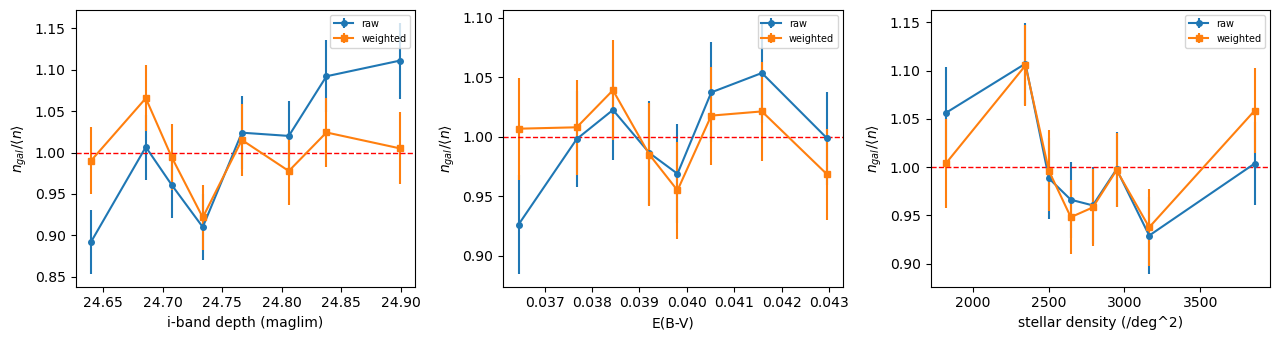

In [29]:
gal_weight_full = np.zeros(len(mask_pix))
pix = pixels_at(gal_ra, gal_dec)
idx = np.clip(np.searchsorted(mask_pix, pix), 0, len(mask_pix) - 1)
found = mask_pix[idx] == pix
np.add.at(gal_weight_full, idx[found], galaxies['weight'].values[found])
gal_weight_valid = gal_weight_full[valid_mask]
n_gal_diag_w = np.bincount(diag_inverse, weights=gal_weight_valid, minlength=len(diag_unique))
mean_density_w = n_gal_diag_w.sum() / diag_area_per_pix_deg2.sum()

n_sys = len(systematic_labels)
ncols = min(3, n_sys)
nrows = int(np.ceil(n_sys / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.3 * ncols, 3.5 * nrows), squeeze=False)
axes = axes.flatten()
for ax, (name, label) in zip(axes, systematic_labels.items()):
    x_r, y_r, yerr_r = density_ratio_trend(diag_values[name], n_gal_diag, diag_area_per_pix_deg2, mean_density)
    x_w, y_w, yerr_w = density_ratio_trend(diag_values[name], n_gal_diag_w, diag_area_per_pix_deg2, mean_density_w)
    ax.errorbar(x_r, y_r, yerr=yerr_r, fmt='o-', ms=4, label='raw')
    ax.errorbar(x_w, y_w, yerr=yerr_w, fmt='s-', ms=4, label='weighted')
    ax.axhline(1.0, color='r', ls='--', lw=1)
    ax.set_xlabel(label)
    ax.set_ylabel(r'$n_{gal}/\langle n \rangle$')
    ax.legend(fontsize=7)
for ax in axes[n_sys:]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()


## Next steps

This notebook runs the full pipeline end to end on a tiny test region: selection, mask,
randoms, raw w(theta), systematics diagnostics, and reweighted w(theta).

- Set `TEST_MODE = False` (Section 1.1) for the full ~113 deg² region.
- Set `FETCH_FULL_SYSTEMATICS = True` (Section 1.1) to fetch all 7 Butler maps and get the
  real systematics diagnostics/weights in Sections 9-10; `False` fetches only the i-band
  depth map (enough for a properly masked w(theta), just without those two sections'
  full set of systematics). Either way, map fetches are cached under `MAP_CACHE_DIR`, so
  switching the flag back and forth, or re-running with the same region, doesn't re-pay the
  slow Butler I/O for maps already fetched.
- The systematics diagnostics and weights here use the full (non-tomographic) MagLim sample;
  redshift-dependent systematics would call for per-bin versions of Sections 9-10.
- The linear weight model is the simplest DES-style approach; an iterative decontamination
  scheme would refit on the residuals of this one.
- `galaxies` columns: `objectId`, `ra`, `dec`, `i_mag`, `z_phot`, `zbin`, `ebv`, `weight`.